# 01 Data coverage and station epochs

Which continuous records does the detection run have? This notebook shows, for 1 September 2025 to 31 January 2026:

- the stations within 100 km of Imsil and the sensor each one contributes (one sensor per station and day: broadband HH, then short-period EL, then accelerometer HG);
- how complete each station's record is, day by day, and how many stations operate each day;
- the evidence for four decisions in `docs/decisions.csv`:
  - **D2:** the co-located pair KWJ2 and KWJU;
  - **D3:** SIDA, a station that started in December 2024;
  - **D7:** why no JU station can be used in this period;
  - **D12:** response epochs that start inside the period.

Days with few stations limit what can be detected. They are an observational limit, not quiet time.

In [1]:
import os, sys, glob, re, subprocess
import numpy as np, pandas as pd
os.environ.setdefault('HELVETICA_DIR', '/home/msseo/Download/Helvetica')
DL = '/home/msseo/works/72.2025_Imsil_swarm/DL_detection'
PROJECT = os.path.dirname(DL)
sys.path.insert(0, f'{DL}/pipeline')
import config, availability, plotstyle  # noqa: F401  (plotstyle registers Helvetica)
import matplotlib.pyplot as plt, matplotlib.dates as mdates
import pygmt
pd.set_option('display.width', 200)
T0, T1 = pd.Timestamp('2025-09-01'), pd.Timestamp('2026-01-31')
SWARM = pd.Timestamp('2025-11-02 20:05')
LAT0, LON0 = config.IMSIL_EPICENTER
st = pd.read_csv(config.STATIONS_CSV)
st['dist_km'] = np.hypot((st.Longitude - LON0) * 111.19 * np.cos(np.radians(LAT0)), (st.Latitude - LAT0) * 111.19)
st = st.sort_values('dist_km').reset_index(drop=True)
av = availability.scan_continuous(cache_csv=None, force=True)
av = av[(av.date >= T0) & (av.date <= T1)]
av['prefix'] = av.channel.str[:2]
print(f'{len(st)} stations in stations.csv; {av.station.nunique()} with linked day files; {len(av)} files, {av.size_mb.sum() / 1e3:.1f} GB')

54 stations in stations.csv; 54 with linked day files; 24624 files, 206.6 GB


## Mirror status

The MARA mirror records every file it should fetch (`continuous_mara/_manifest/manifest.csv`, one row per station and sensor).
The detection run is allowed only when every row of a year is verified.

In [2]:
man = pd.read_csv(f'{PROJECT}/continuous_mara/_manifest/manifest.csv')
g = man.groupby('year').agg(stations=('sta', 'nunique'), rows=('status', 'size'), verified=('status', lambda s: int((s == 'verified').sum())),
                            files=('n_files', 'sum'), gb=('gb', 'sum'), gb_local=('gb_local', 'sum')).round(1)
display(g)
mirror_complete = bool((man.status == 'verified').all())
print('mirror complete:', mirror_complete)

,stations,rows,verified,files,gb,gb_local
year,,,,,,
2025,54,54,54,19602,165.1,165.1
2026,54,54,54,5022,41.5,41.5


mirror complete: True


## Stations and the sensor each one contributes

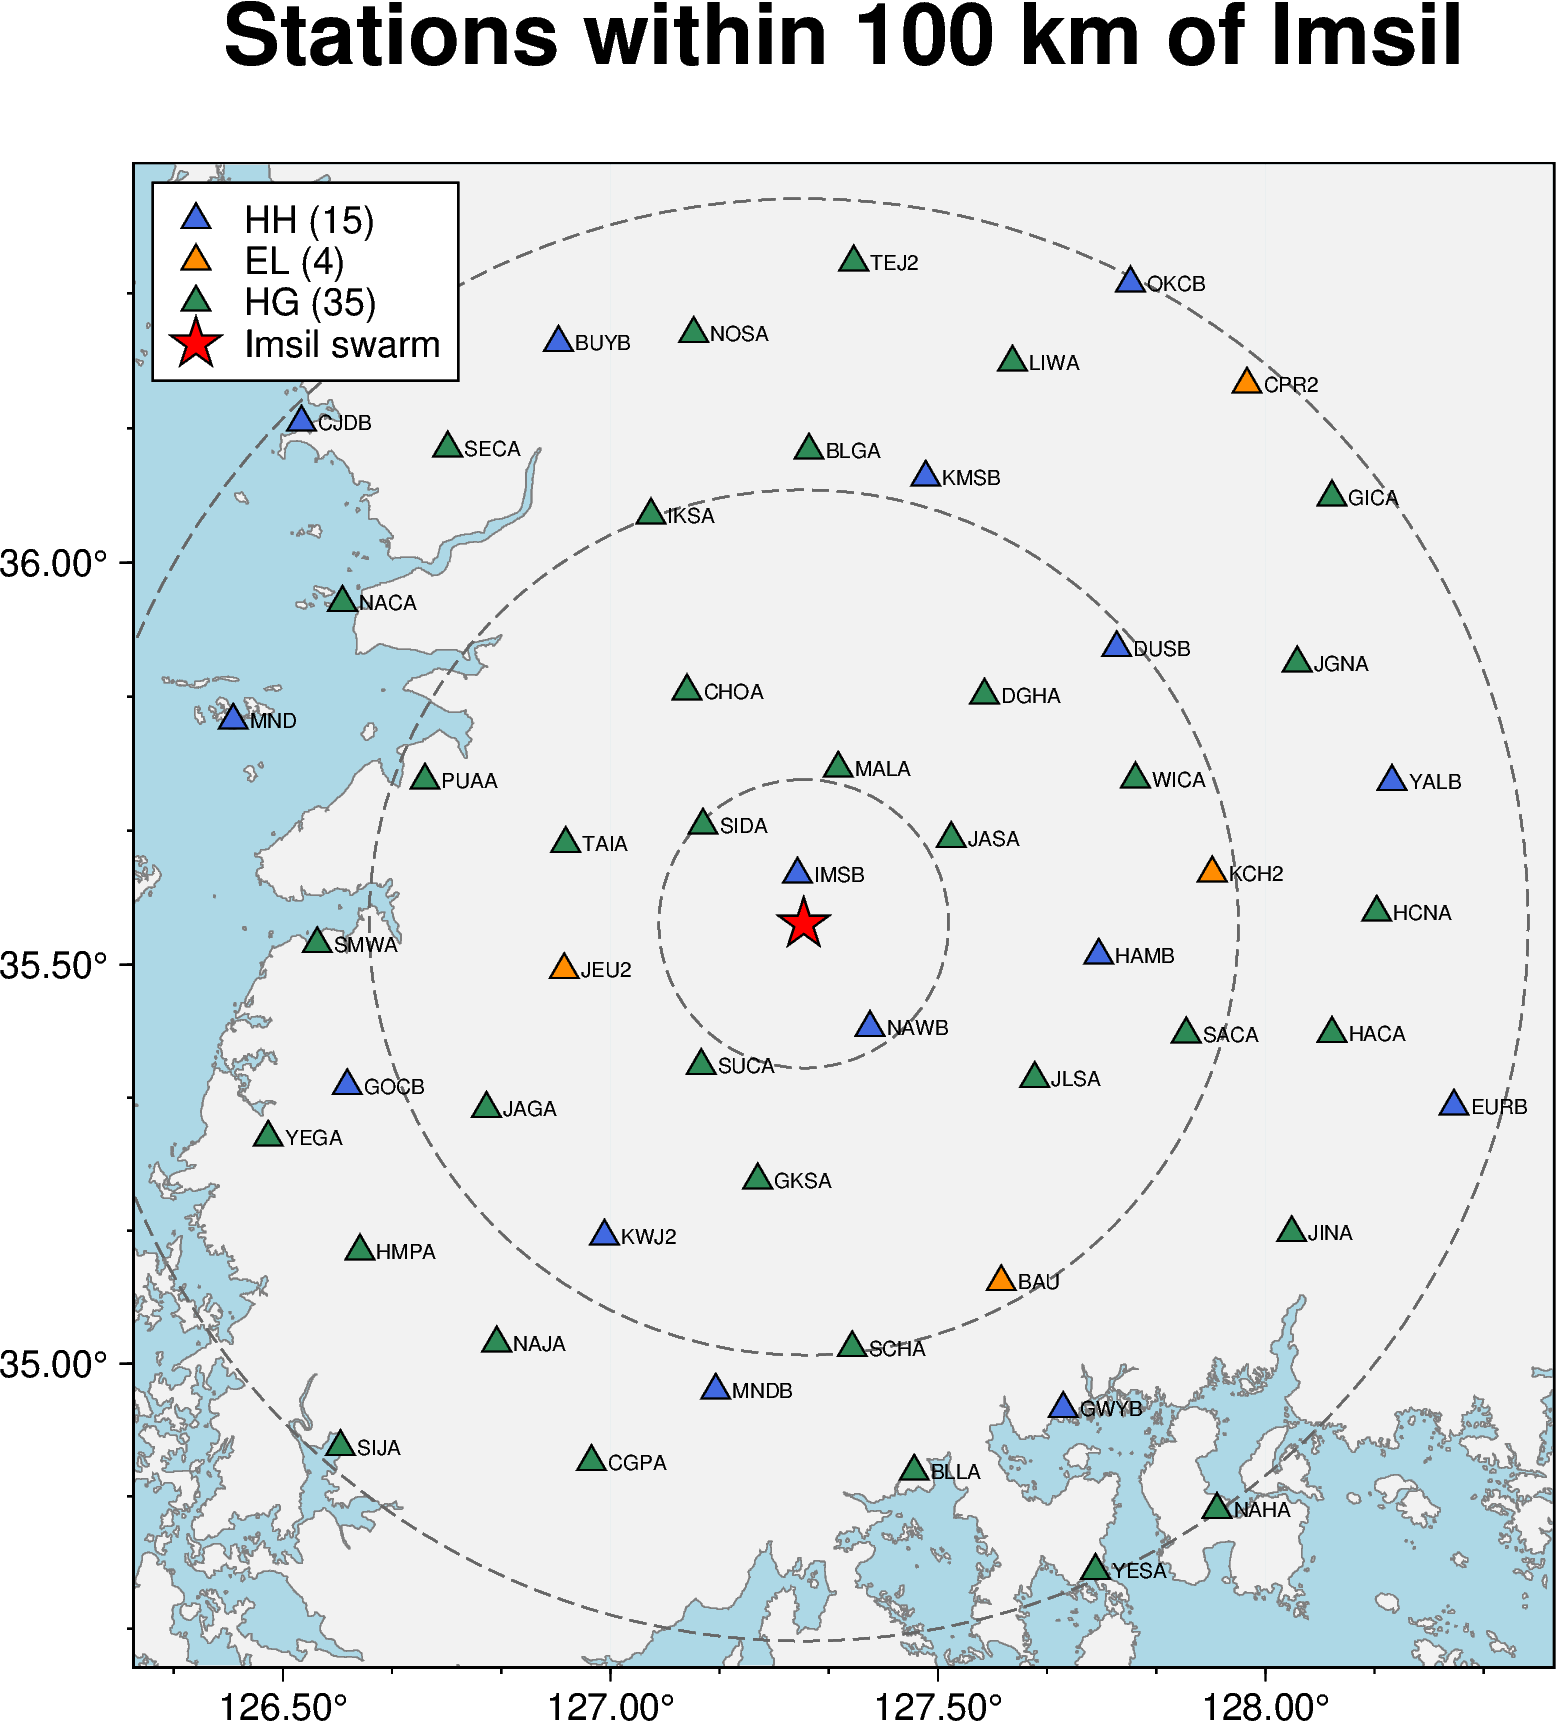

,Network,Code,dist_km,Sensor,prefixes_used
0,KS,IMSB,6.9,HH,HH
1,KS,NAWB,17.0,HH,HH
2,KS,SIDA,19.5,HG,HG
3,KS,MALA,22.1,HG,HG
4,KS,JASA,23.6,HG,HG
5,KS,SUCA,24.2,HG,HG
6,KS,JEU2,33.7,EL,EL
7,KS,TAIA,34.7,HG,HG
8,KS,CHOA,36.1,HG,HG
9,KS,GKSA,36.2,HG,HG


In [3]:
used = av.groupby('station').prefix.agg(lambda p: '/'.join(sorted(set(p)))).rename('prefixes_used')
st = st.merge(used, left_on='Code', right_index=True, how='left')
cls = st.prefixes_used.fillna('none').map(lambda p: p if p in ('HH', 'EL', 'HG') else ('mixed' if p != 'none' else 'none'))
colors = {'HH': 'royalblue', 'EL': 'darkorange', 'HG': 'seagreen', 'mixed': 'purple', 'none': 'gray'}
fig = pygmt.Figure()
pygmt.config(FORMAT_GEO_MAP='ddd.xx', MAP_FRAME_TYPE='plain', FONT_ANNOT_PRIMARY='9p', FONT_LABEL='9p')
region = [st.Longitude.min() - 0.15, st.Longitude.max() + 0.15, st.Latitude.min() - 0.12, st.Latitude.max() + 0.12]
fig.basemap(region=region, projection='M12c', frame=['af', '+tStations within 100 km of Imsil'])
fig.coast(land='gray95', water='lightblue', shorelines='0.3p,gray50')
for r_km in (20, 60, 100):
    fig.plot(x=[LON0], y=[LAT0], style=f'E-{2 * r_km}k', pen='0.5p,gray40,-')
for c, col in colors.items():
    s = st[cls == c]
    if len(s):
        fig.plot(x=s.Longitude, y=s.Latitude, style='t0.28c', fill=col, pen='0.4p,black', label=f'{c} ({len(s)})')
fig.text(x=st.Longitude + 0.025, y=st.Latitude, text=st.Code, font='5p,Helvetica,black', justify='LM')
fig.plot(x=[LON0], y=[LAT0], style='a0.45c', fill='red', pen='0.4p,black', label='Imsil swarm')
fig.legend(position='JTL+jTL+o0.15c', box='+gwhite+p0.5p')
fig.show()
display(st[['Network', 'Code', 'dist_km', 'Sensor', 'prefixes_used']].round(1))

## Day-by-day completeness

Each cell is one station and day. Its shade is the fraction of the day actually recorded, read from the miniSEED headers of the vertical component (union of the trace time spans), so a fully recorded day is black and gaps are white.
File volume is not used, because compressed files are 10–15 % smaller on quiet days.
Stations are ordered by distance from Imsil, nearest at the top. The red line marks the start of the swarm.

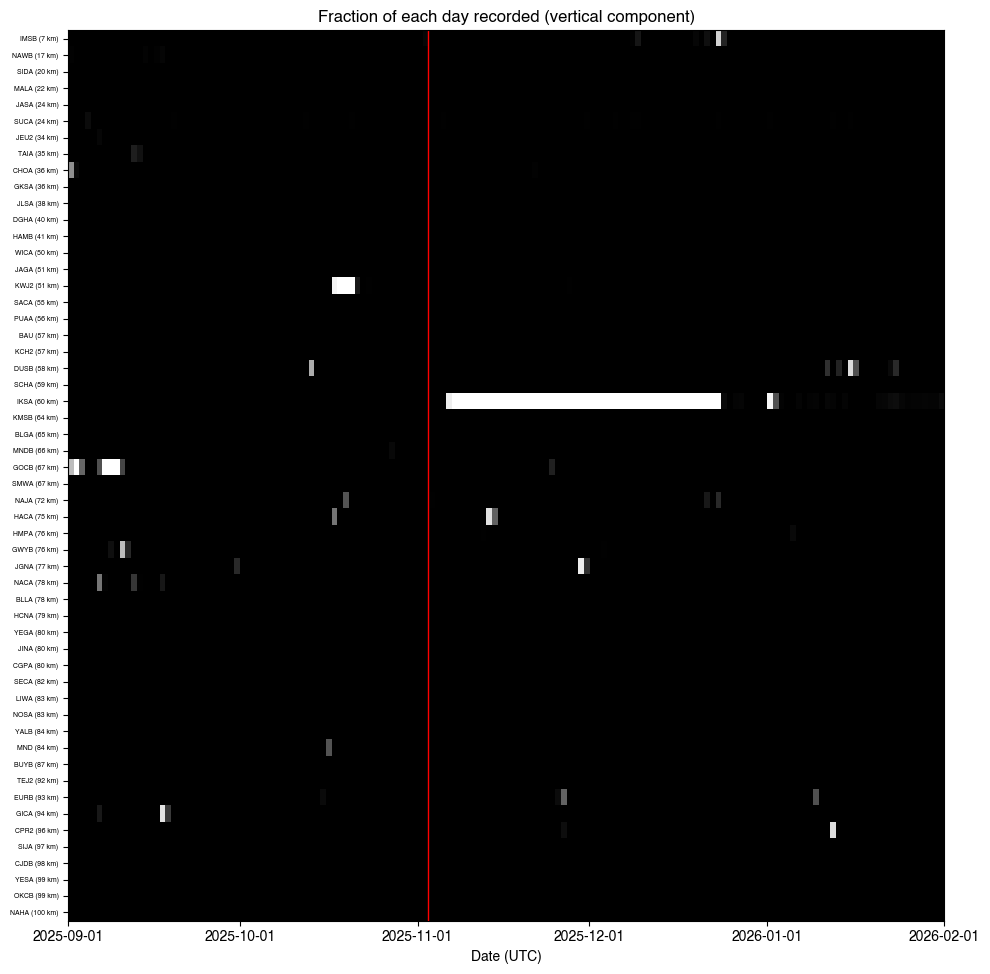

,channels,first,last,days_in_period,full_days,recorded_fraction,total_gb
station,,,,,,,
IMSB,HHE/HHN/HHZ,2025-09-01,2026-01-31,153,146,0.993,4.69
NAWB,HHE/HHN/HHZ,2025-09-01,2026-01-31,153,149,1.000,4.37
SIDA,HGE/HGN/HGZ,2025-09-01,2026-01-31,153,153,1.000,2.69
MALA,HGE/HGN/HGZ,2025-09-01,2026-01-31,153,153,1.000,2.96
JASA,HGE/HGN/HGZ,2025-09-01,2026-01-31,153,153,1.000,3.51
SUCA,HGE/HGN/HGZ,2025-09-01,2026-01-31,153,152,0.998,2.85
JEU2,ELE/ELN/ELZ,2025-09-01,2026-01-31,153,152,1.000,4.99
TAIA,HGE/HGN/HGZ,2025-09-01,2026-01-31,153,151,0.999,3.03
CHOA,HGE/HGN/HGZ,2025-09-01,2026-01-31,153,150,0.997,4.39


station-days with less than 99 % recorded: 85
on the swarm days (2-3 Nov):


,station,date,missing_h
3071,IMSB,2025-11-02,0.57


In [4]:
from concurrent.futures import ThreadPoolExecutor
from obspy import read
def covered_seconds(path):
    # union of trace time spans inside the day, from the miniSEED headers only
    try:
        st = read(path, headonly=True)
    except Exception:
        return 0.0
    if not len(st):
        return 0.0
    d0 = st[0].stats.starttime.datetime.replace(hour=0, minute=0, second=0, microsecond=0)
    iv = sorted((max(0.0, (t.stats.starttime.datetime - d0).total_seconds()), min(86400.0, (t.stats.endtime.datetime - d0).total_seconds() + t.stats.delta)) for t in st)
    tot, cur0, cur1 = 0.0, iv[0][0], iv[0][1]
    for a, b in iv[1:]:
        if a > cur1:
            tot += cur1 - cur0; cur0, cur1 = a, b
        else:
            cur1 = max(cur1, b)
    return tot + cur1 - cur0
zf = av[av.channel.str.endswith('Z')].copy()
zf['path'] = [f'{config.CONTINUOUS}/{r.dirnet}/{r.station}/{r.channel}.D/{r.network}.{r.station}..{r.channel}.D.{r.year}.{r.doy:03d}' for r in zf.itertuples()]
with ThreadPoolExecutor(16) as ex:   # header reads only; threads avoid the process pool inside the kernel
    zf['seconds'] = list(ex.map(covered_seconds, zf.path, chunksize=64))
sd = zf.groupby(['network', 'station', 'date'], as_index=False).seconds.max()
sd['completeness'] = (sd.seconds / 86400).clip(upper=1.0)
days = pd.date_range(T0, T1, freq='D')
order = [c for c in st.Code if c in set(sd.station)]
mat = sd.pivot_table(index='station', columns='date', values='completeness').reindex(index=order, columns=days)
fig, ax = plt.subplots(figsize=(10, 0.16 * len(order) + 1.2))
ax.imshow(mat.fillna(0).to_numpy(), aspect='auto', cmap='Greys', vmin=0, vmax=1, interpolation='nearest',
          extent=[mdates.date2num(days[0]), mdates.date2num(days[-1] + pd.Timedelta(days=1)), len(order), 0])
ax.axvline(mdates.date2num(SWARM), color='red', lw=1)
ax.set_yticks(np.arange(len(order)) + 0.5); ax.set_yticklabels([f'{c} ({d:.0f} km)' for c, d in zip(order, st.set_index('Code').loc[order, 'dist_km'])], fontsize=5)
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
ax.set_xlabel('Date (UTC)'); ax.set_title('Fraction of each day recorded (vertical component)')
plt.tight_layout(); plt.show()
cov = availability.coverage_table(av).set_index('station').reindex(order)
cov['days_in_period'] = mat.notna().sum(axis=1)
cov['full_days'] = (mat >= 0.99).sum(axis=1)
cov['recorded_fraction'] = mat.mean(axis=1).round(3)
display(cov[['channels', 'first', 'last', 'days_in_period', 'full_days', 'recorded_fraction', 'total_gb']])
gaps = sd[sd.completeness < 0.99].assign(missing_h=lambda g: ((1 - g.completeness) * 24).round(2)).sort_values(['date', 'station'])
print(f'station-days with less than 99 % recorded: {len(gaps)}')
swarm_gaps = gaps[gaps.date.isin([pd.Timestamp("2025-11-02"), pd.Timestamp("2025-11-03")])]
print('on the swarm days (2-3 Nov):'); display(swarm_gaps[['station', 'date', 'missing_h']] if len(swarm_gaps) else 'none')

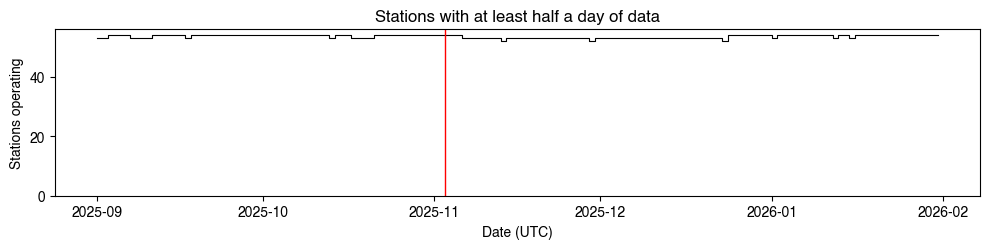

stations operating per day: median 54, minimum 52 on 2025-11-13; on the swarm day 54


In [5]:
cnt = sd[sd.completeness >= 0.5].groupby('date').station.nunique().reindex(days, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.step(days, cnt.values, where='post', color='black', lw=0.8)
ax.axvline(SWARM, color='red', lw=1)
ax.set_ylabel('Stations operating'); ax.set_xlabel('Date (UTC)'); ax.set_title('Stations with at least half a day of data')
ax.set_ylim(0, len(st) + 2); plt.tight_layout(); plt.show()
print(f'stations operating per day: median {int(cnt.median())}, minimum {int(cnt.min())} on {cnt.idxmin().date()}; on the swarm day {int(cnt.loc[SWARM.normalize()])}')

## Sensor changes inside the period

A station that switches sensor, for example from accelerometer to broadband, changes the waveforms the picker sees, and the templates later.
The table lists every station whose contributing sensor changes inside the period, with the dates.

In [6]:
pp = av.drop_duplicates(['station', 'date', 'prefix']).sort_values(['station', 'date'])
sw = []
for sta, g in pp.groupby('station'):
    seq = g.groupby('date').prefix.first()
    ch = seq[seq != seq.shift()]
    if len(ch) > 1:
        sw.append(dict(station=sta, changes='; '.join(f'{d.date()} {p}' for d, p in ch.items())))
switches = pd.DataFrame(sw)
display(switches if len(switches) else 'no sensor changes inside the period')

'no sensor changes inside the period'

## Evidence for decisions D2, D3, D7 and D12

**D2, KWJ2 and KWJU.** The two codes have the same coordinates. If both record on the same days, HYPOINVERSE would count one site twice.
KWJU is not in `stations.csv` (default: dropped, as in Haenam), so its MARA listing is read directly.

In [7]:
sds = '<mara-sds-root>'
def mara_days(sta, year, d0, d1):
    cmd = f'ls {sds}/{year}/KS/{sta}/*/ 2>/dev/null'
    r = subprocess.run(['ssh', '-o', 'BatchMode=yes', '<user>@<mara-host>', cmd], capture_output=True, text=True, timeout=120)
    doys = {int(f.split('.')[-1]) for f in r.stdout.split() if f.count('.') == 6}
    return {pd.Timestamp(f'{year}-01-01') + pd.Timedelta(days=d - 1) for d in doys if d0 <= d <= d1}
kwju = mara_days('KWJU', 2025, 244, 365) | mara_days('KWJU', 2026, 1, 31)
kwj2 = set(sd[sd.station == 'KWJ2'].date)
shared_kwj = len(kwju & kwj2)
print(f'KWJU days on MARA in the period: {len(kwju)}; KWJ2 linked days: {len(kwj2)}; shared days: {shared_kwj}')

KWJU days on MARA in the period: 153; KWJ2 linked days: 150; shared days: 150


**D3, SIDA** (19.5 km from Imsil; operating since 2024-12-22; absent from the master StationXML, so its response comes from the KMA RESP files):

In [8]:
sida_days = int(cov.loc['SIDA', 'days_in_period']) if 'SIDA' in cov.index else 0
print(f'SIDA: {sida_days} days with data in the period; channels {cov.loc["SIDA", "channels"] if "SIDA" in cov.index else "-"}')
print('SIDA RESP files:', sorted(os.path.basename(f) for f in glob.glob(f'{PROJECT}/data/stations/responses/fetched/extracted/RESP.KS.SIDA..*')))

SIDA: 153 days with data in the period; channels HGE/HGN/HGZ
SIDA RESP files: ['RESP.KS.SIDA..HGE', 'RESP.KS.SIDA..HGN', 'RESP.KS.SIDA..HGZ']


**D7, JU stations.** The JNU network (JU) is listed in `JU_station.xml`, but the XML gives no start dates for these stations.
The evidence is therefore the MARA archive itself: for each JU station within 100 km of Imsil, the first and last day with data in 2025 and 2026.

In [9]:
from obspy import read_inventory
inv = read_inventory(f'{PROJECT}/data/stations/JU_station.xml')
ju = pd.DataFrame([dict(station=s.code, dist_km=np.hypot((s.longitude - LON0) * 111.19 * np.cos(np.radians(LAT0)), (s.latitude - LAT0) * 111.19))
                   for n in inv for s in n]).query('dist_km <= 100').sort_values('dist_km').round(1).reset_index(drop=True)
def mara_ju(sta):
    out = {}
    for y in (2025, 2026):
        r = subprocess.run(['ssh', '-o', 'BatchMode=yes', '<user>@<mara-host>', f'ls {sds}/{y}/JU/{sta}/*/ 2>/dev/null'], capture_output=True, text=True, timeout=120)
        doys = sorted({int(f.split('.')[-1]) for f in r.stdout.split() if f.count('.') == 6})
        out[y] = (pd.Timestamp(f'{y}-01-01') + pd.Timedelta(days=doys[0] - 1), pd.Timestamp(f'{y}-01-01') + pd.Timedelta(days=doys[-1] - 1)) if doys else None
    return out
cov_ju = {s: mara_ju(s) for s in ju.station}
ju['first_day_on_MARA'] = [min([v[0] for v in cov_ju[s].values() if v], default=pd.NaT) for s in ju.station]
ju['days_in_period'] = [sum(1 for v in cov_ju[s].values() if v and v[0] <= T1) for s in ju.station]
display(ju)
ju_in_period = int((ju.first_day_on_MARA <= T1).sum())
print(f'JU stations within 100 km: {len(ju)}; with data on MARA before {T1.date()}: {ju_in_period}')

,station,dist_km,first_day_on_MARA,days_in_period
0,JB07,3.0,2026-09-01,0
1,JB06,23.0,2026-09-01,0
2,JB03,28.6,2026-09-01,0
3,JN05,34.1,2026-09-01,0
4,JB05,44.9,2026-09-01,0
5,JN04,48.2,2026-09-01,0
6,JB01,49.0,2026-09-01,0
7,JB08,49.1,2026-09-01,0
8,JB02,59.8,2026-09-01,0
9,JN03,62.0,2026-09-01,0


JU stations within 100 km: 18; with data on MARA before 2026-01-31: 0


**D12, response epochs starting inside the period.** A new response epoch usually means new or re-installed equipment. Before the horizontal components of such a station are used for template matching, their orientation must be shown to be unchanged.

In [10]:
rows = []
for f in glob.glob(f'{PROJECT}/data/stations/responses/fetched/extracted/RESP.KS.*'):
    sta, cha = os.path.basename(f).split('.')[2], os.path.basename(f).split('.')[4]
    if sta not in set(st.Code):
        continue
    m = re.search(r'Start date:\s+(\d{4}),(\d{3})', open(f).read())
    if m:
        t = pd.Timestamp(f'{m.group(1)}-01-01') + pd.Timedelta(days=int(m.group(2)) - 1)
        rows.append(dict(station=sta, channel=cha, epoch_start=t))
ep = pd.DataFrame(rows)
inside = ep[(ep.epoch_start >= T0) & (ep.epoch_start <= T1)].groupby('station').agg(epoch_start=('epoch_start', 'min'), channels=('channel', lambda c: '/'.join(sorted(set(c))))).reset_index()
inside = inside.merge(st[['Code', 'dist_km']], left_on='station', right_on='Code').drop(columns='Code').round(1)
display(inside)

,station,epoch_start,channels,dist_km
0,HMPA,2025-09-09,HGE/HGN/HGZ,76.3
1,KWJ2,2025-10-28,HGE/HGN/HGZ/HHE/HHN/HHZ,51.4
2,NAWB,2025-09-16,HGE/HGN/HGZ/HHE/HHN/HHZ,17.0


## Comprehensive summary

In [11]:
summary = pd.DataFrame([
    ('Mirror complete (all manifest rows verified)', mirror_complete),
    ('Stations in stations.csv', len(st)),
    ('Stations with data in the period', int(av.station.nunique())),
    ('Median stations operating per day', int(cnt.median())),
    ('Minimum stations operating per day', f'{int(cnt.min())} on {cnt.idxmin().date()}'),
    ('Stations operating on the swarm day (2 Nov 2025)', int(cnt.loc[SWARM.normalize()])),
    ('Stations with a sensor change inside the period', len(switches)),
    ('D2: KWJU / KWJ2 shared days', shared_kwj),
    ('D3: SIDA days with data', sida_days),
    ('D7: JU stations within 100 km with data before 1 Feb 2026 (MARA)', ju_in_period),
    ('D12: stations with a response epoch starting inside the period', ', '.join(inside.station) if len(inside) else 'none'),
], columns=['quantity', 'value'])
display(summary)
print('Take-home points')
print(f'  - The detection run will see {int(av.station.nunique())} KS stations; on a typical day {int(cnt.median())} of them record.')
print(f'  - D2: KWJU and KWJ2 share {shared_kwj} days, so keeping both would count one site twice; ' + ('dropping KWJU (default) is supported.' if shared_kwj else 'no overlap, so either can be kept.'))
print(f'  - D7: {ju_in_period} JU stations within 100 km have data on MARA before 1 Feb 2026 (the nearest, JB07 at 3 km, starts {ju.first_day_on_MARA.min().date() if ju.first_day_on_MARA.notna().any() else "never"}), so the run is KS only.')
print('  - D12: the stations listed above changed response epoch inside the period; their horizontals stay out of FMF S windows until their orientation is checked.')
print('Reproduce: ./run_imsil.sh mirror status 2025; ./run_imsil.sh link run; ./run_imsil.sh epochs run; then re-run this notebook.')

,quantity,value
0,Mirror complete (all manifest rows verified),True
1,Stations in stations.csv,54
2,Stations with data in the period,54
3,Median stations operating per day,54
4,Minimum stations operating per day,52 on 2025-11-13
5,Stations operating on the swarm day (2 Nov 2025),54
6,Stations with a sensor change inside the period,0
7,D2: KWJU / KWJ2 shared days,150
8,D3: SIDA days with data,153
9,D7: JU stations within 100 km with data before...,0


Take-home points
  - The detection run will see 54 KS stations; on a typical day 54 of them record.
  - D2: KWJU and KWJ2 share 150 days, so keeping both would count one site twice; dropping KWJU (default) is supported.
  - D7: 0 JU stations within 100 km have data on MARA before 1 Feb 2026 (the nearest, JB07 at 3 km, starts 2026-09-01), so the run is KS only.
  - D12: the stations listed above changed response epoch inside the period; their horizontals stay out of FMF S windows until their orientation is checked.
Reproduce: ./run_imsil.sh mirror status 2025; ./run_imsil.sh link run; ./run_imsil.sh epochs run; then re-run this notebook.
